Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



             Acciaiuoli Albizzi Barbadori Bischeri Castellani Ginori Guadagni
Acciaiuoli            0       0         0        0          0      0        0
Albizzi               0       0         0        0          0      0        0
Barbadori             0       0         0        0          1      1        0
Bischeri              0       0         0        0          0      0        1
Castellani            0       0         1        0          0      0        0
Ginori                0       0         1        0          0      0        0
Guadagni              0       0         0        1          0      0        0
Lamberteschi          0       0         0        1          1      0        1
Medici                0       0         1        0          0      1        0
Pazzi                 0       0         0        0          0      0        0
Peruzzi               0       0         1        1          1      0        0
Pucci                 0       0         0        0          0   

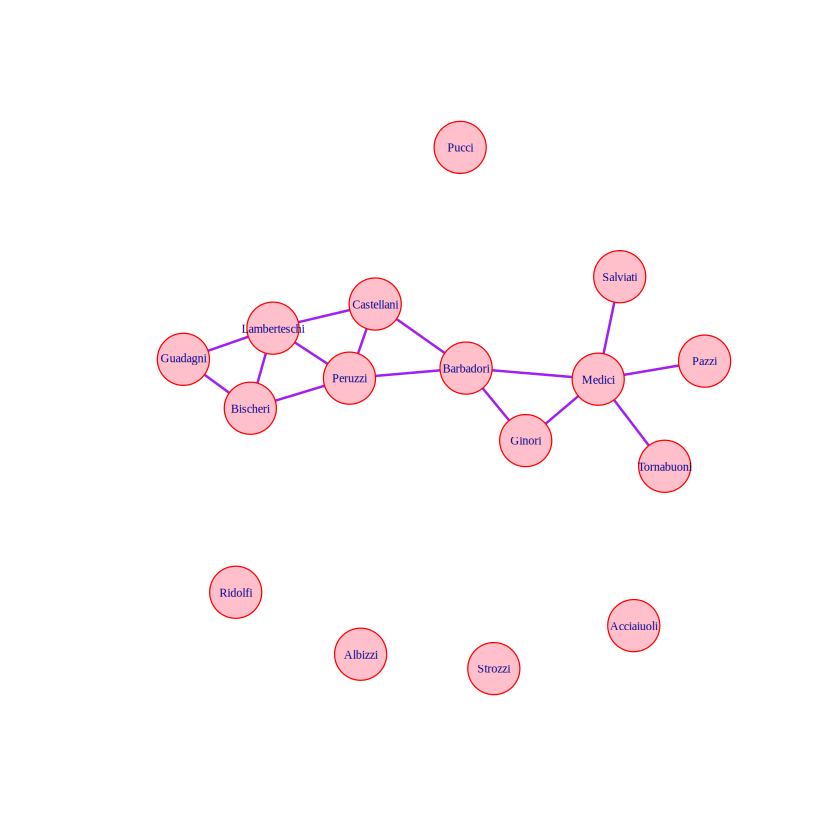

Сводка
IGRAPH e676550 UN-- 16 15 -- 
+ attr: name (v/c)
Razmer grafa - 16 
Плотность по формуле - 0.125 
Плотность с помощью функции -  0.125 
Количество компонент связности - 6 
Диаметр - 5 
Коэффициент кламтеризации -  0.4166667 
            n_i C_D       C_C        C_B        C_I
1     Barbadori 0.4 0.5882353 0.55555556 0.12446815
2      Bischeri 0.3 0.4000000 0.05555556 0.08898359
3    Castellani 0.3 0.5000000 0.11111111 0.10457651
4        Ginori 0.2 0.4545455 0.00000000 0.09531249
5      Guadagni 0.2 0.3125000 0.00000000 0.07656303
6  Lamberteschi 0.4 0.4166667 0.13333333 0.09837087
7        Medici 0.5 0.5263158 0.53333333 0.11089878
8         Pazzi 0.1 0.3571429 0.00000000 0.06388631
9       Peruzzi 0.4 0.5263158 0.30000000 0.10916767
10     Salviati 0.1 0.3571429 0.00000000 0.06388631
11   Tornabuoni 0.1 0.3571429 0.00000000 0.06388631
   1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21
1  0 1 0 1 0 0 0 1 0  0  0  0  0  0  0  1  0  1  0  0  1
2  0 0 0 0 0 1 1 0 0  0  0  0 

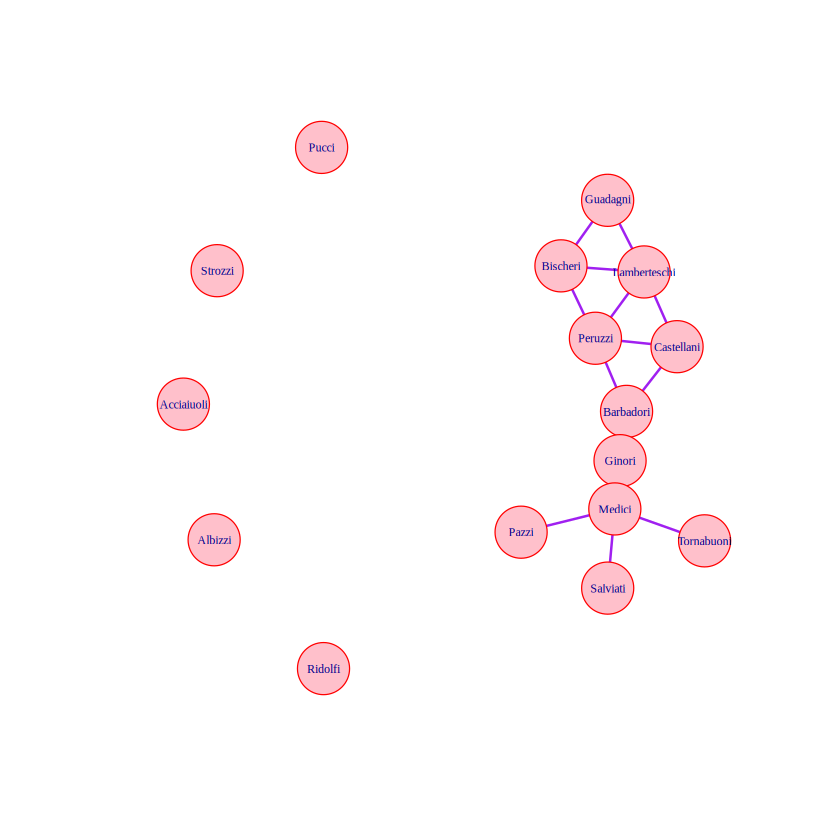

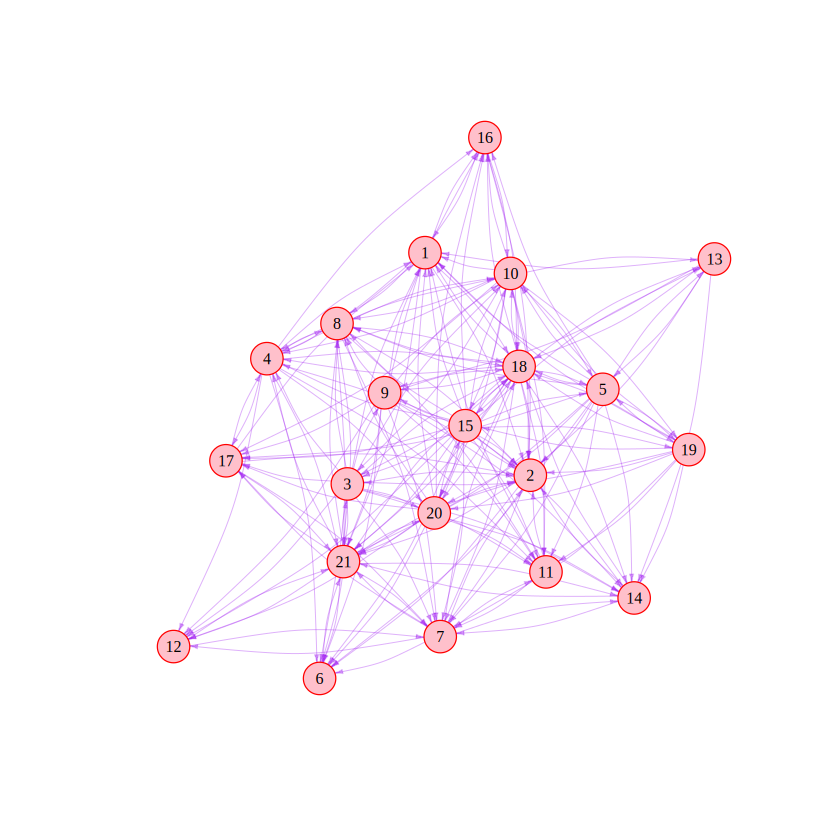

Сводка
IGRAPH 8a01e58 DN-- 21 190 -- 
+ attr: name (v/c)
Размер сети - 21 
Плотность по формуле - 0.452381 
Плотность с помощью функции -  0.452381 
Слабые компоненты связности - 1 
Сильные компоненты связности - 1 
Диаметр - 3 
Коэффициент кластеризации -  0.7345088 
   n_i  P_D       P_P        P_R
1    1 0.65 0.6666667 0.05781874
2    2 0.90 0.9090909 0.09728403
3    3 0.25 0.5555556 0.02979140
4    4 0.40 0.6250000 0.05029805
5    5 0.25 0.5000000 0.02127487
6    6 0.50 0.6666667 0.06034269
7    7 0.65 0.7407407 0.07465725
8    8 0.50 0.6666667 0.05399703
9    9 0.20 0.4878049 0.01772633
10  10 0.45 0.5714286 0.03987937
11  11 0.55 0.6666667 0.05406294
12  12 0.35 0.5882353 0.03943579
13  13 0.20 0.4878049 0.01919999
14  14 0.50 0.6666667 0.04976382
15  15 0.20 0.4878049 0.02144754
16  16 0.40 0.5714286 0.03954469
17  17 0.45 0.6451613 0.04684524
18  18 0.75 0.8000000 0.07586604
19  19 0.20 0.4878049 0.01919999
20  20 0.40 0.6060606 0.04207271
21  21 0.75 0.8000000 0.08949150


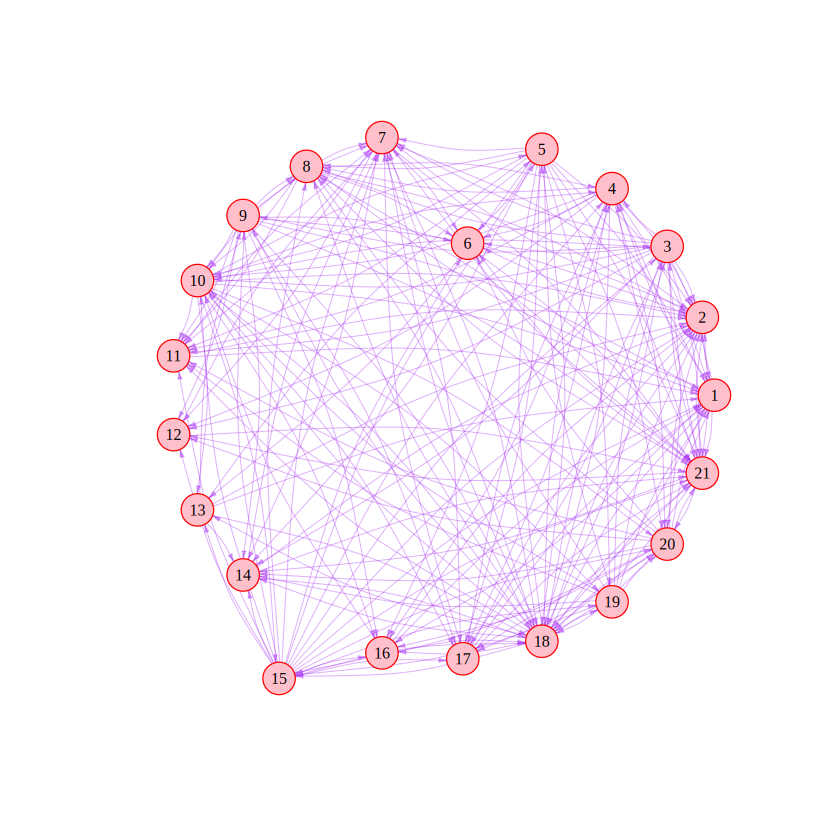

In [3]:
install.packages("igraph")

library(igraph)

m <- read.csv("florentine_business.csv", header = FALSE, sep = ",", skip = 2)

m <- as.matrix(m)

lines <- readLines("florentine_business.csv")

# (3)
nodnames <- strsplit(lines[2], ",")[[1]]

nodnames <- trimws(nodnames)

# (3)
rownames(m) <- nodnames
colnames(m) <- nodnames

# (1)
print(m)

# (4)
gr <- graph_from_adjacency_matrix(m, mode = "undirected", weighted = NULL, diag = FALSE)
# (2)
el <- as_edgelist(gr)
print(el[1:5,])
# (4)
print(gr)

# (5)
coord_Fr <- layout_with_fr(gr)

coord_Kk <- layout_with_kk(gr)

plot(gr,
     layout = coord_Fr*4,
     vertex.size = 20,
     vertex.color = "pink",
     vertex.frame.color = "red",
     vertex.label = V(gr)$name,
     vertex.label.cex = 0.6,
     edge.color = "purple",
     edge.width = 2)

plot(gr,
     layout = coord_Kk*4,
     vertex.size = 20,
     vertex.color = "pink",
     vertex.frame.color = "red",
     vertex.label = V(gr)$name,
     vertex.label.cex = 0.6,
     edge.color = "purple",
     edge.width = 2)

# (6)
cat("Сводка\n")
summary(gr)

# (7)
v <- vcount(gr)
e <- ecount(gr)
cat("Razmer grafa -", v,"\n")

d <- (2*e)/((v-1)*v)

cat("Плотность по формуле -", d, "\nПлотность с помощью функции - ", edge_density(gr), "\n")

comp <- components(gr)$no

cat("Количество компонент связности -", comp,"\n")

di <- diameter(gr)

cat("Диаметр -", di,"\n")

clast <- transitivity(gr, type = "global")

cat("Коэффициент кламтеризации - ", clast, "\n")

# (8)
keep <- rowSums(m) + colSums(m) > 0
m_u <- m[keep, keep]
gr_u <- graph_from_adjacency_matrix(m_u, mode = "undirected", diag = FALSE)
n <- vcount(gr_u)

C_D <- degree(gr_u) / (n - 1)
C_C <- closeness(gr_u, normalized = TRUE)
C_B <- betweenness(gr_u, directed = FALSE, normalized = TRUE)

B <- diag(rowSums(m_u)) - m_u + 1
Cm <- solve(B)
I_raw <- 1 / (diag(Cm) + (sum(diag(Cm)) - 2*rowSums(Cm)) / n)
C_I <- I_raw / sum(I_raw)

res <- data.frame(n_i = rownames(m_u), C_D, C_C, C_B, C_I, row.names = NULL)
print(res)


m_2 <- read.csv("krackhardt_advice.csv", header = FALSE, sep = ",", skip = 2)

m_2 <- as.matrix(m_2)

rownames(m_2) <- seq_len(nrow(m_2))
colnames(m_2) <- seq_len(ncol(m_2))

# (1)
print(m_2)

# (4)
gr2 <- graph_from_adjacency_matrix(m_2, mode = "directed", weighted = NULL, diag = FALSE)
# (2)
el2 <- as_edgelist(gr2)
print(el2[1:5,])
# (4)
print(gr2)

# (5)
coord_Fr2 <- layout_with_fr(gr2)

coord_Kk2 <- layout_with_kk(gr2)

plot(gr2,
     layout = coord_Fr2,
     vertex.size = 12,
     vertex.color = "pink",
     vertex.frame.color = "red",
     vertex.label = V(gr2)$name,
     vertex.label.cex = 0.8,
     vertex.label.color = "black",
     edge.color = adjustcolor("purple", alpha.f = 0.35),
     edge.width = 0.8,
     edge.arrow.size = 0.3,
     edge.arrow.width = 0.8,
     edge.curved = 0.15)

plot(gr2,
     layout = coord_Kk2,
     vertex.size = 12,
     vertex.color = "pink",
     vertex.frame.color = "red",
     vertex.label = V(gr2)$name,
     vertex.label.cex = 0.8,
     vertex.label.color = "black",
     edge.color = adjustcolor("purple", alpha.f = 0.35),
     edge.width = 0.8,
     edge.arrow.size = 0.3,
     edge.arrow.width = 0.8,
     edge.curved = 0.15)

# (6)
cat("Сводка\n")
summary(gr2)

# (7)
v2 <- vcount(gr2)
e2 <- ecount(gr2)
cat("Размер сети -", v2,"\n")

d2 <- e2/((v2-1)*v2)

cat("Плотность по формуле -", d2, "\nПлотность с помощью функции - ", edge_density(gr2), "\n")

comp2 <- components(gr2, mode = "weak")$no
comp2_s <- components(gr2, mode = "strong")$no

cat("Слабые компоненты связности -", comp2, "\nСильные компоненты связности -", comp2_s, "\n")

di2 <- diameter(gr2, directed = TRUE, weights = NA)

cat("Диаметр -", di2,"\n")

clast2 <- transitivity(gr2, type = "global")

cat("Коэффициент кластеризации - ", clast2, "\n")

# (10)
P_D <- degree(gr2, mode = "in") / (v2 - 1)

dist_in <- distances(gr2, mode = "in")
diag(dist_in) <- NA
P_P <- sapply(seq_len(v2), function(i) {
  dd <- dist_in[i, ]
  dd <- dd[!is.na(dd) & is.finite(dd)]
  if (length(dd) == 0) return(0)
  (length(dd) / (v2 - 1)) / mean(dd)
})

P_R <- eigen_centrality(gr2, directed = TRUE, scale = FALSE)$vector
P_R <- P_R / sum(P_R)

prestige_table <- data.frame(n_i = rownames(m_2), P_D, P_P, P_R, row.names = NULL)
print(prestige_table)